  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached tzdata-2026.5-py2.py3-none-any.whl.metadata (1.4 kB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   -- ------------------------------------- 0.8/11.3 MB 2.4 MB/s eta 0:00:05
   ------ --------------------------------- 1.8/11.3 MB 3.9 MB/s eta 0:00:03
   ------------ --------------------------- 3.7/11.3 MB 5.5 MB/s eta 0:00:02
   -------------------- ------------------- 5.8/11.3 MB 6.8 MB/s eta 0:00:01
   --------------------------- ------------ 7.9/11.3 MB 7.3 MB/s eta 0:00:01
   ------------------------------------ --- 10.2/11.3 MB 8.0 MB/s eta 0:00:01
   ---------------------------------------- 11.3/11.3 MB 8.1 MB/s  0:00:01
Using cached tzdata-2026.5-py2.py3-none-any.whl (347 kB)

   ----

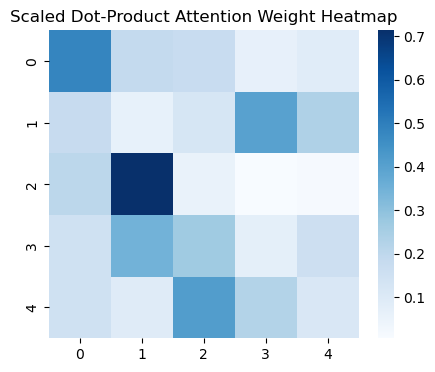

In [1]:
%pip install seaborn
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import seaborn as sns

def scaled_dot_product_attention(Q, K, V, mask=None):
    d_k = Q.size(-1)
    attn_scores = torch.matmul(Q, K.transpose(-2, -1)) / torch.sqrt(torch.tensor(d_k, dtype=torch.float32))
    if mask is not None:
        attn_scores = attn_scores.masked_fill(mask == 0, -1e9)
    attn_weights = torch.softmax(attn_scores, dim=-1)
    output = torch.matmul(attn_weights, V)
    return output, attn_weights

batch_size = 1
seq_len = 5
d_k = 64
Q = torch.randn(batch_size, seq_len, d_k)
K = torch.randn(batch_size, seq_len, d_k)
V = torch.randn(batch_size, seq_len, d_k)

out, attn_w = scaled_dot_product_attention(Q,K,V)
print("Attention权重矩阵 shape:", attn_w.shape)

plt.figure(figsize=(5,4))
sns.heatmap(attn_w[0].detach().numpy(), annot=False, cmap="Blues")
plt.title("Scaled Dot-Product Attention Weight Heatmap")
plt.show()